In [ ]:
# DECISION TREE CLASSIFIER FOR STUDENT PERFORMANCE SCORE PREDICTION
# Goal: predict 'pass' or 'needs support' from  student information

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay

In [6]:
data = pd.read_csv('Decision_Tree_Student_Performance_Dataset.csv.xls')
data

,Study_Hours_Per_Week,Attendance_Percent,Previous_Exam_Score,Assignments_Completed_Out_Of_10,Sleep_Hours_Per_Night,Class_Participation_1_to_5,Result
0,9.0,75,84,4,7.3,4,Pass
1,4.7,75,75,9,6.9,1,Needs Support
2,10.4,98,94,5,8.0,3,Pass
3,11.0,86,42,9,7.7,3,Pass
4,1.8,79,61,6,3.4,3,Needs Support
...,...,...,...,...,...,...,...
1495,4.5,73,44,4,8.8,4,Needs Support
1496,9.0,67,58,8,6.7,1,Needs Support
1497,4.3,100,33,10,7.3,1,Needs Support
1498,10.3,92,69,8,6.4,5,Pass


In [7]:
# inspect the data

print("first five rows of the dataset:")
print(data.head())
print("\\nDataset size(rows, columns):", data.shape)
print("\\nHow many of each result?")
print(data['Result'].value_counts())

first five rows of the dataset:
   Study_Hours_Per_Week  Attendance_Percent  Previous_Exam_Score  \
0                   9.0                  75                   84   
1                   4.7                  75                   75   
2                  10.4                  98                   94   
3                  11.0                  86                   42   
4                   1.8                  79                   61   

   Assignments_Completed_Out_Of_10  Sleep_Hours_Per_Night  \
0                                4                    7.3   
1                                9                    6.9   
2                                5                    8.0   
3                                9                    7.7   
4                                6                    3.4   

   Class_Participation_1_to_5         Result  
0                           4           Pass  
1                           1  Needs Support  
2                           3           Pass  
3   

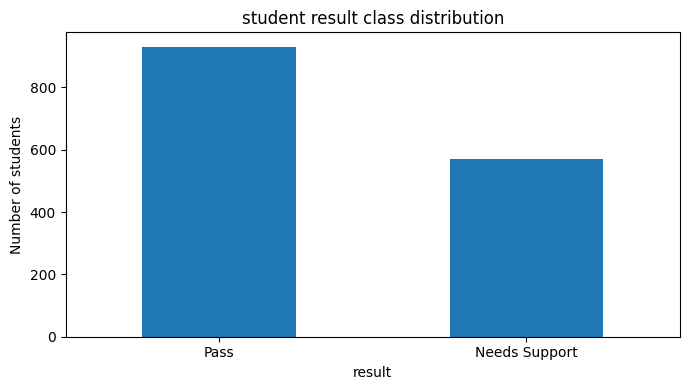

In [11]:
data['Result'].value_counts().reindex(['Pass', "Needs Support"]).plot(
    kind='bar', rot=0, figsize=(7, 4), title="student result class distribution"
)
plt.xlabel("result")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()


In [13]:
# sepetate features and target variable
X = data.drop('Result', axis=1)
y = data['Result']

In [16]:
#split the data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42,
    stratify=y
)
print("\\nTraining rows:", len(X_train), "\nTesting rows:", len(X_test))

\nTraining rows: 1200 
Testing rows: 300


In [29]:
tree_model = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=8,
    random_state=42
)



In [30]:
tree_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,8
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [34]:
# predict result for unseen test data
predictions = tree_model.predict(X_test)

# evaluate the model
print("\\nAccuracy:", round(accuracy_score(y_test, predictions) * 100,2), "%")
print("\\nClassification report:")
print(classification_report(y_test, predictions, zero_division=0))


\nAccuracy: 74.67 %
\nClassification report:
               precision    recall  f1-score   support

Needs Support       0.66      0.69      0.68       114
         Pass       0.81      0.78      0.79       186

     accuracy                           0.75       300
    macro avg       0.73      0.74      0.73       300
 weighted avg       0.75      0.75      0.75       300



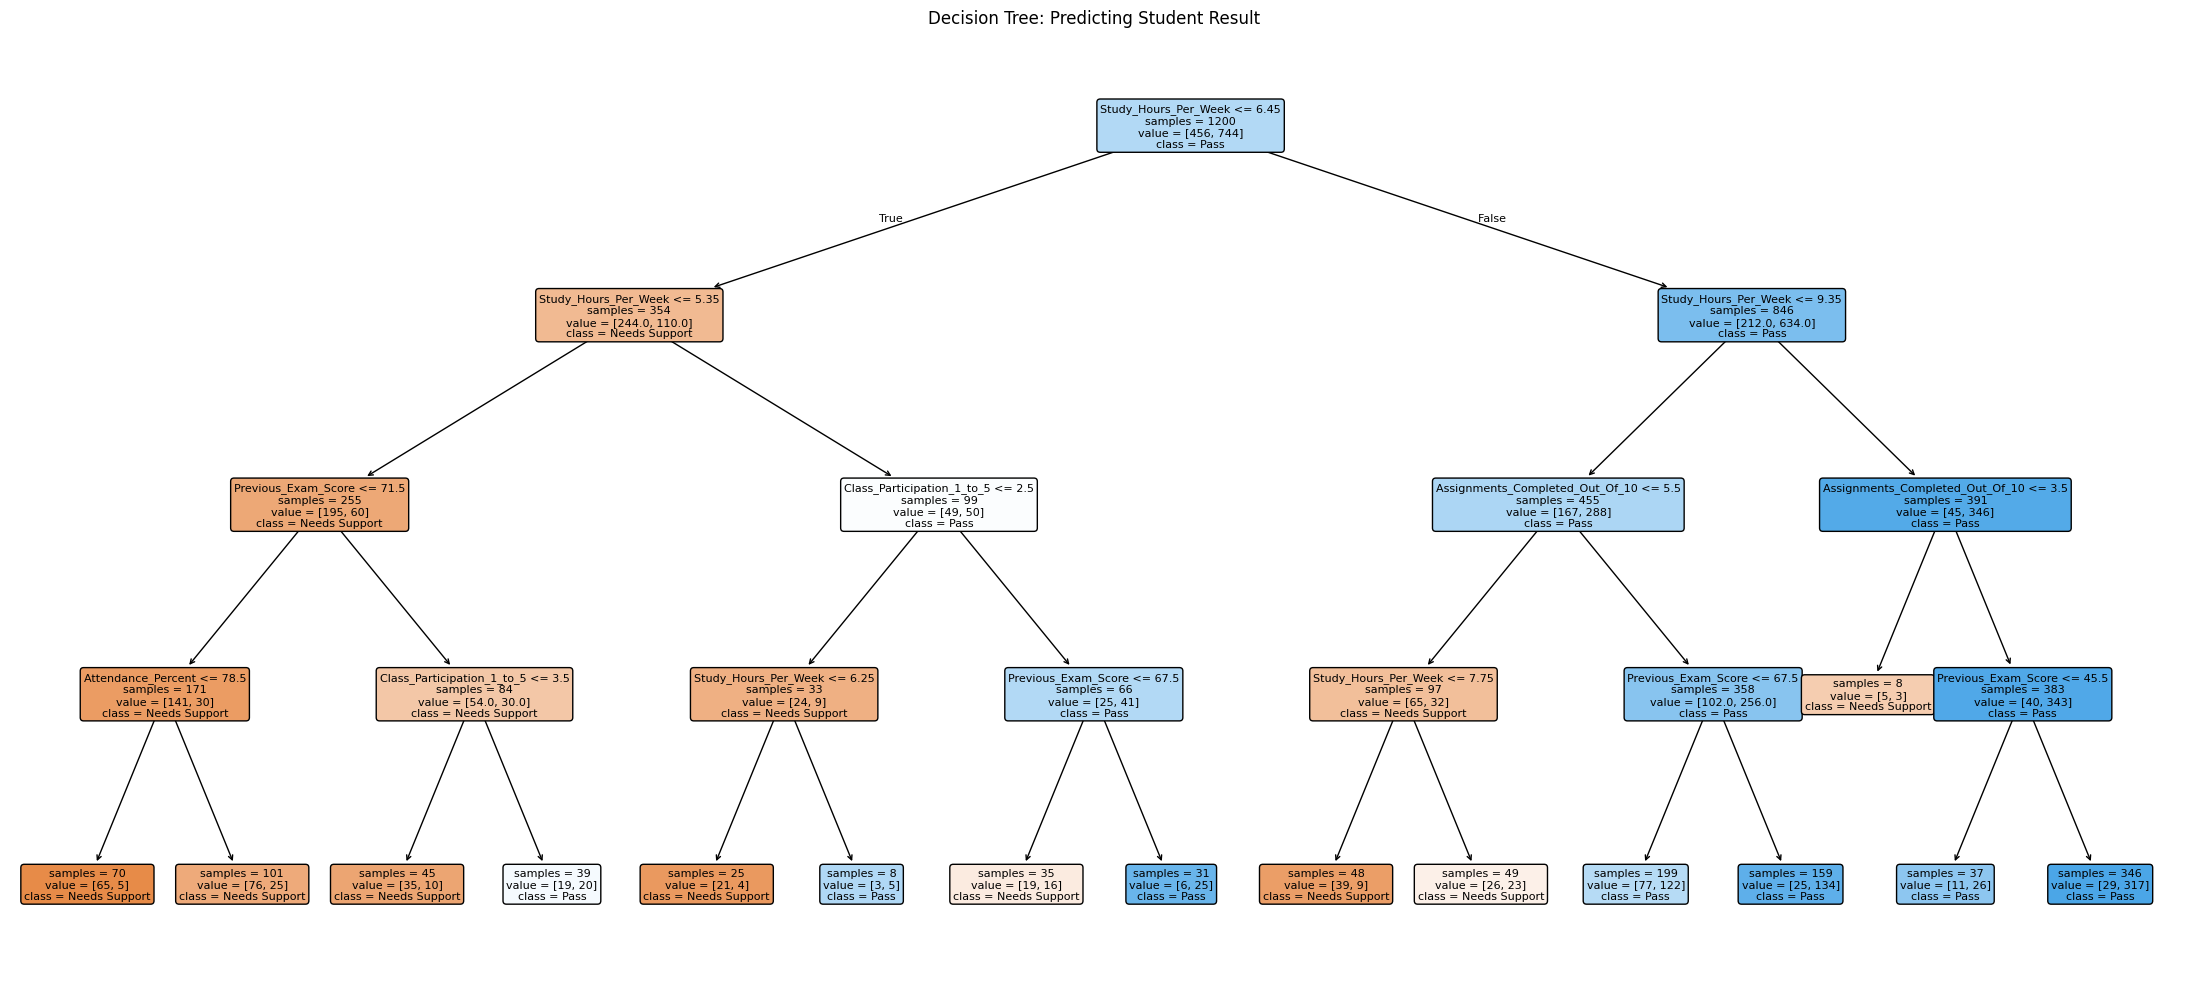

In [36]:
# plot the learned decision tree
plt.figure(figsize=(22, 10))
plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=8
)
plt.title('Decision Tree: Predicting Student Result')
plt.tight_layout()
plt.show()

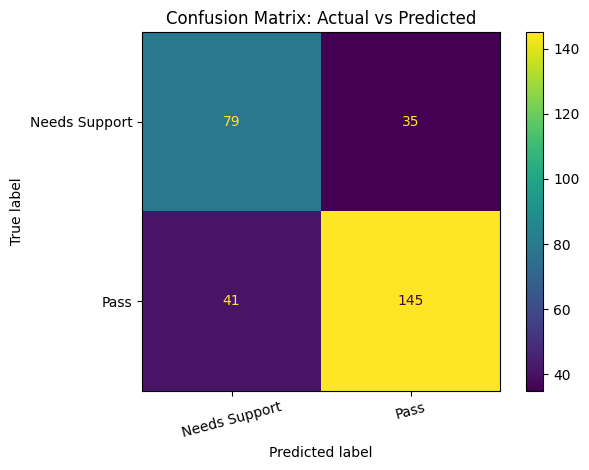

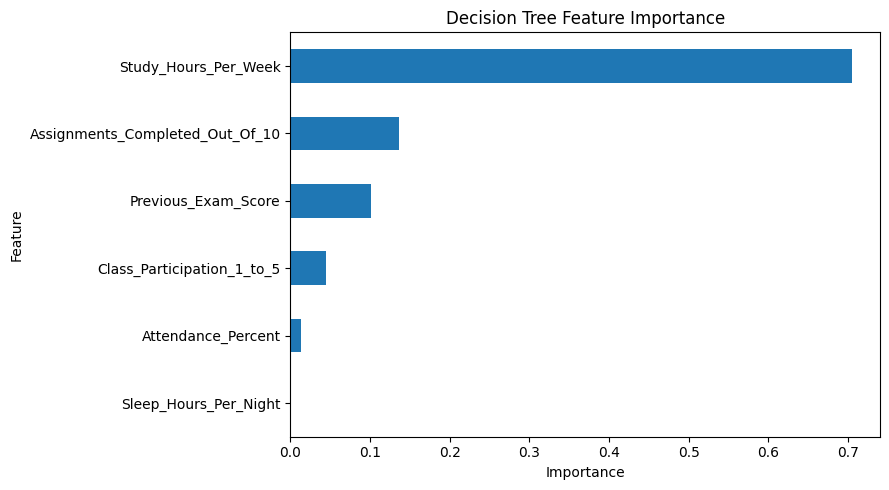

In [38]:
# plot a confusion matrix (actual labels compared with predictions)
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=tree_model.classes_, xticks_rotation=15
)
plt.title('Confusion Matrix: Actual vs Predicted')
plt.tight_layout()
plt.show()

# optional visaulization 2: features importance
importance = pd.Series(
    tree_model.feature_importances_, index=X.columns
).sort_values()
importance.plot(kind="barh", figsize=(9, 5), title="Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()